<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Статистические свойства в модели линейной регрессии</span></h2>

In [1]:
import warnings
from typing import Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms

from sklearn.base import RegressorMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import HuberRegressor, LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from statsmodels.regression.linear_model import RegressionResultsWrapper

from linear_models_tools import plot_regression_intervals


warnings.filterwarnings("ignore")
sns.set(style="whitegrid", font_scale=1.2, palette="Set2")

RANDOM_STATE = 42

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Квартиры в Москве</span>

Загрузим датасет 2024 года с данными по стоимости квартир в Москве (<a href="https://www.kaggle.com/datasets/ivan314sh/prices-of-moscow-apartments">источник</a>).

В датасете представлены данные о цене москвоской квартиры и различных характеристиках квартиры. Наша задача &mdash; предсказать цену квартиры по ее описанию.

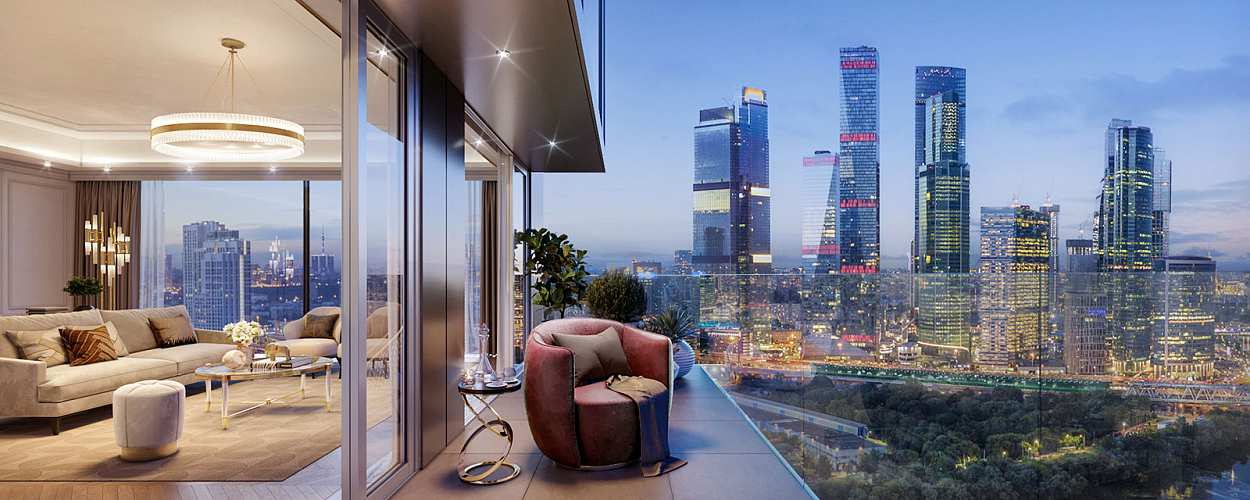

**Описание колонок**

1. **price** — цена объекта недвижимости в рублях (RUB).  
2. **min_to_metro** — примерное время (в минутах) до ближайшего метро.  
3. **region_of_moscow** — административный округ Москвы, в котором находится объект.
4. **total_area** — общая площадь объекта в квадратных метрах.  
5. **living_area** — жилая площадь объекта в квадратных метрах (помещения, предназначенные для проживания).  
6. **floor** — этаж, на котором расположен объект.  
7. **number_of_floors** — общее количество этажей в здании.  
8. **construction_year** — год постройки здания.  
9. **is_new** — бинарный признак, указывающий, является ли объект новостройкой.  
10. **is_apartments** — бинарный признак, указывающий, классифицируется ли объект как апартаменты.  
    - Значение **0** — можно официально зарегистрироваться по месту жительства.  
    - Значение **1** — регистрация невозможна (например, апартаменты без инфраструктуры). <br/>    <br/>    
11. **ceiling_height** — высота потолков в метрах.  
12. **number_of_rooms** — количество комнат (включая спальни, гостиную и т.д.).  
13. **link** — URL-ссылка на страницу объекта с подробной информацией.


In [2]:
flats = pd.read_csv("moscow_flats_dataset.csv")
flats = flats[flats.total_area < 300]  # отфильтруем слишком большие квартиры, так как их мало
flats = flats[flats.price < 600 * 1e6]  # отфильтруем слишком дорогие квартиры, так как их мало
flats["price"] = flats["price"] / 1e6  # будем измерять цены в миллионах
flats.head()

,price,min_to_metro,region_of_moscow,total_area,living_area,floor,number_of_floors,construction_year,is_new,is_apartments,ceiling_height,number_of_rooms,link
0,31.633073,24.0,ЮАО,64.2,32.4,11.0,16.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/293204033/
1,29.293000,9.0,СВАО,78.1,NaN,9.0,27.0,2022.0,1.0,0.0,NaN,2.0,https://www.cian.ru/sale/flat/294033524/
2,30.349669,5.0,ЮАО,72.4,33.6,3.0,24.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/300712697/
3,31.845511,19.0,ЮАО,69.2,NaN,2.0,12.0,2024.0,1.0,0.0,2.97,2.0,https://www.cian.ru/sale/flat/300228448/
4,38.810000,27.0,ЗАО,66.9,24.8,9.0,14.0,2023.0,1.0,0.0,3.00,2.0,https://www.cian.ru/sale/flat/299262105/


In [3]:
flats.info()

<class 'pandas.DataFrame'>
Index: 6921 entries, 0 to 6982
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              6921 non-null   float64
 1   min_to_metro       6807 non-null   float64
 2   region_of_moscow   6853 non-null   str    
 3   total_area         6921 non-null   float64
 4   living_area        4495 non-null   float64
 5   floor              6921 non-null   float64
 6   number_of_floors   6921 non-null   float64
 7   construction_year  5732 non-null   float64
 8   is_new             6910 non-null   float64
 9   is_apartments      6910 non-null   float64
 10  ceiling_height     5032 non-null   float64
 11  number_of_rooms    6921 non-null   float64
 12  link               6921 non-null   str    
dtypes: float64(11), str(2)
memory usage: 1.0 MB


Разделим данные на обучающую и тестовую части

In [4]:
train, test = train_test_split(flats, test_size=0.1, random_state=RANDOM_STATE)

Посмотрим для начала на зависимость цены квартиры от общей площади и попробуем предсказать цену только по ней.

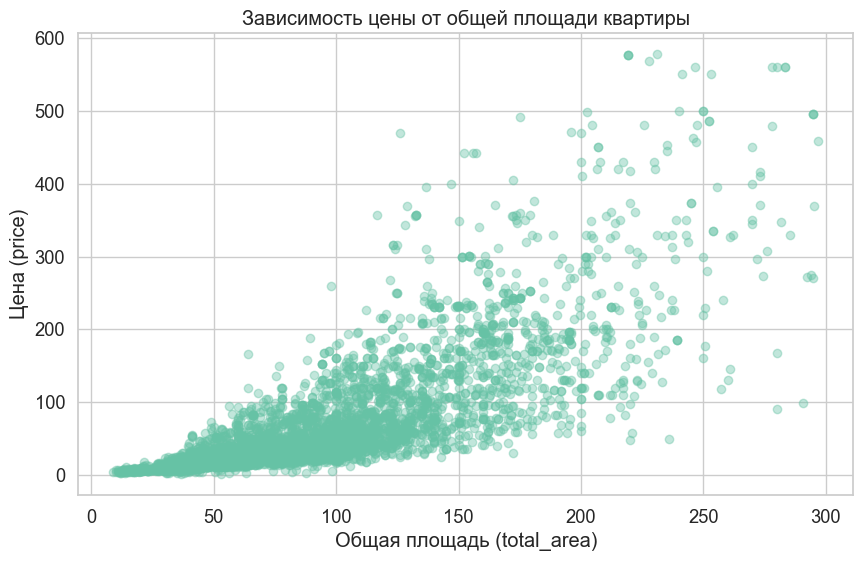

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(train["total_area"], train["price"], alpha=0.4)
plt.xlabel("Общая площадь (total_area)")
plt.ylabel("Цена (price)")
plt.title("Зависимость цены от общей площади квартиры")
plt.show()

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">Линейная модель в случае гомоскедастичности</span>

Сначала обучим линейную регрессию, для этого воспользуемся реализацией `statsmodels.regression.linear_model.OLS`. 

> Модель можно задавать двумя способами.
> 
> 1. **Матричный подход** (похожий на `sklearn`)
> 
>     Как обычно передаем таргет и матрицу признаков. Обратите внимание, что в отличии от `sklearn`, здесь порядок аргументов обратный: **сначала `y` (таргет), потом `X` (признаки)**.<br/><br/>
> 
> 
> 2. **Подход с использованием формул**
> 
>     Этот метод позволяет описать модель на специальном языке формул, что часто бывает нагляднее. Общая структура такой формулы:
> 
>     `target ~ features_1 + features_2 + ... + features_d`
> 
>     Эта формула в математическом виде представима как
>     $$y(x) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_d x_d$$
> 
>     Общие правила определения формулы:
>     * Символ `~` (тильда) является центральным элементом. Его можно прочитать как «объясняется через» или «зависит от». Слева указывается таргет, справа — признаки.  
>     * Справа от тильды перечисляются признаки (столбцы `DataFrame`), которые должны войти в модель в качестве признаков. Их имена записываются через знак `+`.
>     * Константа обычно добавляется в модель автоматически. Если же необходимо явно исключить её, это можно сделать, добавив в конец формулы `-1` или `+0`.
>     * Категориальные признаки можно передать как `C(category_feature)`, они будут преобразованы с помощью one-hot encoding.
>     * Конструкция `feature_1:feature_2` позволяет задать новый признак, равный произведению двух исходных. Это позволяет модели учитывать эффект взаимодействия двух признаков.
>     * Конструкция `feature_1*feature_2` автоматически включает все индивидуальные эффекты и все возможные взаимодействия между указанными признаками. Он эквивалентен конструкции `feature_1 + feature_2 + feature_1:feature_2`
>     * Арифметические выражения в формулу можно включать в с помощью `I(expression)`, например `I(x**2)`.
    

In [6]:
linear = smf.ols("price ~ total_area", train)
lm_results = linear.fit()

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.1</span> <span style="color:inherit;">Простые свойства</span>

Метод `fit` возвращает объект типа `statsmodels.regression.linear_model.RegressionResults`, который содержит всю информацию о модели. В нём можно найти:

* **Общая информация о модели**: параметры обучения, число наблюдений, R², проверка значимости модели в целом, логарифм функции правдоподобия, информационные критерии (AIC, BIC).  
* **Информация о коэффициентах**: оценки коэффициентов, стандартные ошибки, t-статистика, p-value, доверительные интервалы.  
* **Анализ остатков**: проверка несмещённости, нормальности, гомоскедастичности.

Сначала посмотрим на **результат модели в целом**, а затем разберём каждый блок по отдельности.


In [7]:
print(lm_results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                 1.079e+04
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:52:30   Log-Likelihood:                -32466.
No. Observations:                6228   AIC:                         6.494e+04
Df Residuals:                    6226   BIC:                         6.495e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -43.2410      1.121    -38.581      0.0

In [8]:
lm_results.summary2().tables[0]

,0,1,2,3
0,Model:,OLS,Adj. R-squared:,0.634
1,Dependent Variable:,price,AIC:,64935.2488
2,Date:,2026-10-13 16:52,BIC:,64948.7224
3,No. Observations:,6228,Log-Likelihood:,-32466.
4,Df Model:,1,F-statistic:,1.079e+04
5,Df Residuals:,6226,Prob (F-statistic):,0.00
6,R-squared:,0.634,Scale:,1974.6


**Общая информация о модели**

* **Dep. Variable:** `price` — зависимая переменная (таргет).  
* **Model:** `OLS` — метод наименьших квадратов.  
* **Method:** `Least Squares` — способ обучения модели.  
* **No. Observations:** `6228` — число наблюдений.  
* **Df Model:** `1` — число признаков (без интерсепта).  
* **Df Residuals:** `6226` — степени свободы остатков.  
* **Covariance Type:** `nonrobust` — предполагается гомоскедастичность.

**Метрики качества модели**

* **R-squared:** `0.634` — доля дисперсии зависимой переменной, объяснённая моделью:
$$
R^2 = 1 - \frac{\sum\limits_{i=1}^{n} \left(Y_i - \widehat{Y}_i\right)^2}{\sum\limits_{i=1}^{n} \left(Y_i - \overline{Y}\right)^2}
$$

* **Adj. R-squared:** `0.634` — скорректированный $R^2$, учитывающий число признаков:
$$
\text{Adj. } R^2 = 1 - (1 - R^2) \frac{n - 1}{n - k - 1}
$$

* **Log-Likelihood:** `-32466` — логарифмическая функция правдоподобия.  

* **AIC/BIC:** информационные критерии, чем меньше, тем лучше модель при прочих равных.






In [9]:
lm_results.summary2().tables[1]

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
Intercept,-43.240961,1.120775,-38.581303,3.488862e-292,-45.438067,-41.043855
total_area,1.211332,0.011664,103.851129,0.000000e+00,1.188466,1.234197


> Столбцы таблицы:
> 
> *   **`Coef.`** &mdash; оценка параметров модели.
> *   **`Std.Err.`** &mdash; оценка стандартного отклонения оценки параметров модели.
> *   **`t`** &mdash; T-статистика, которую мы использовали для построения доверительного интервала, с подставленным значением $\theta_j=0$.
> *   **`P>|t|`** &mdash; p-value для проверки статистических гипотез, его пояснение мы опустим.
> *   **`[0.025` и `0.975]`** &mdash; границы 95% доверительного интервала

*Важно!* Пока что все свойства получены в предположении гомоскедастичности.

Посмотрим на оценки `intercept` и коэффициента перед `totsp`

- `Intercept = −43.24` — формальный сдвиг, не имеет физического смысла (цена при нулевой площади).  
- `totsp = 1.21` — при увеличении площади квартиры на $1\ м^2$ цена в среднем растёт на $1.21$ млн рублей.  




Предсказания на тестовых данных можно получить с помощью `predict`

In [10]:
test_predictions = lm_results.predict(test)

mae = mean_absolute_error(test["price"], test_predictions)
r2 = r2_score(test["price"], test_predictions)

print(f"R^2: {r2:.4f}")
print(f"MAE: {mae:.2f}")

R^2: 0.6067
MAE: 26.54


Давайте посмотрим как наша модель ложится на реальные данные

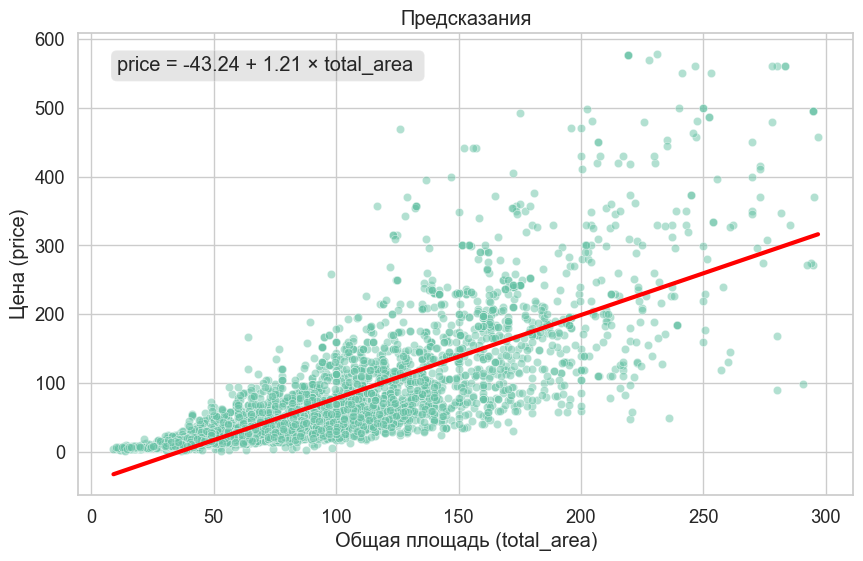

In [11]:
# Создадим сетку значений для total_area и получим предсказания
totsp_grid = np.linspace(train["total_area"].min(), train["total_area"].max(), 100)
grid_data = pd.DataFrame({"total_area": totsp_grid})
grid_predictions = lm_results.predict(grid_data)

intercept = lm_results.params["Intercept"]
slope = lm_results.params["total_area"]
formula_text = f"price = {intercept:+.2f} + {slope:.2f} × total_area "

plt.figure(figsize=(10, 6))
sns.scatterplot(x="total_area", y="price", data=train, alpha=0.5)
plt.plot(totsp_grid, grid_predictions, color="red", linewidth=3)
plt.xlabel("Общая площадь (total_area)")
plt.ylabel("Цена (price)")
plt.title("Предсказания")
plt.text(
    0.05,
    0.95,
    formula_text,
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="grey", alpha=0.2),
)

plt.show()

Что мы видим? Красную линию, которая, конечно, показывает тренд, однако для прямого предсказания она явно не годится. __Любая__ точечная оценка скорее всего будет неверна, для любой оценки нужен будет доверительный интервал.

Использую только модель, мы не можем подставить площадь в формулу и получить достоверную цену. С вероятностью ~ 100% мы получим неверные данные и заказчик очень расстроится и отругает нас за такую бесполезную модель.

**Интервалы для коэффициентов**

Statsmodels позволяет легко получать доверительные интервалы для коэффициентов модели. Это помогает оценить не только среднее значение влияния признака, но и его возможную погрешность, что дает представление о **масштабе и надежности** этого влияния.

На практике такие интервалы необходимы для обоснованных решений. Например, в экономике, медицине или инженерии важно учитывать не просто точечную оценку, а диапазон, в котором результат остается устойчивым. Это позволяет избежать случайных колебаний и минимизировать риски.

Интервалы строятся на основе оценки матрицы ковариаций оценки коэффициентов модели. Получить ее можно следующим образом.

In [12]:
lm_results.cov_params()

,Intercept,total_area
Intercept,1.256137,-0.011303
total_area,-0.011303,0.000136


Метод OLS предоставляет доверительные интервалы для оценок коэффициентов. Это интервалы для самих параметров модели ($\theta_0, \theta_1$), а не для её предсказаний.

*Важно!* Пока что все свойства получены в предположении гомоскедастичности.

In [13]:
lm_results.conf_int()

,0,1
Intercept,-45.438067,-41.043855
total_area,1.188466,1.234197


#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2.2</span> <span style="color:inherit;">Доверительные и предсказательные интервалы</span>

Для нового наблюдения $x_0$ **доверительный интервал** уровня доверия $1-\alpha$ для *среднего* таргета $\mathsf E Y_0 =  x_0^\top \theta$ в условиях **гомоскедастичности** имеет следующий вид
$$
\left( x_0^\top\widehat{\theta} \ \pm \ T_{n-d, 1-\alpha/2} \, \widehat{\sigma} \,
\sqrt{x_0^\top (X^\top X)^{-1} x_0} \right)
$$

В свою очередь **предсказательный интервал** уровня доверия $1-\alpha$ для *фактического* $Y_0 =  x_0^\top \theta + \varepsilon_0$ таргета в условиях **гомоскедастичности**

$$
\left( x_0^\top\widehat{\theta} \ \pm \ T_{n-d, 1-\alpha/2} \, \widehat{\sigma} \,
\sqrt{x_0^\top (X^\top X)^{-1} x_0 + 1} \right)
$$

Доверительный интервал уже, поскольку учитывает только неопределённость оценки среднего значения таргета. Предсказательный интервал дополнительно учитывает случайную ошибку на новом объекте, поэтому включает больше источников неопределённости и получается шире. То есть предсказательный интервал должен накрывать **около 95% всех наблюдаемых точек**, а не только средние значения. Это и учитывает добавка «+1».

> Эту формулу мы получили, исходя из дисперсии предсказания и дисперсии шума на новом объекте. Повторим основные рассуждения. Пусть $x_0$ — новый объект, а $\widehat{Y_0} = \widehat{y}(x_0) = x_0^\top\widehat{\theta}$ — предсказание на нём. Тогда фактическое значение таргета на новом объекте имеет вид
>
> $$  Y_0 = x_0^\top\theta + \varepsilon_0, $$
>
> где $\varepsilon_0$ — шум на новом объекте, независимый от шума на обучающей выборке и, следовательно, от $\widehat{\theta}$.
>
> Дисперсия предсказания с учётом шума на новом объекте равна
>
> $$\mathsf D(Y_0) = x_0^\top\mathsf D(\widehat{\theta})x_0 -\mathsf D(\varepsilon_0).\   $$
>
> Учитывая, что в условиях гомоскедастичности $\mathsf D(\widehat{\theta}) = \sigma^2(X^\top X)^{-1}$ и $\mathsf D(\varepsilon_0) = \sigma^2$, получаем
>
> $$\mathsf D(Y_0) = \sigma^2\left[x_0^\top(X^\top X)^{-1}x_0+1\right]. $$
>
> Далее извлекаем корень из полученной дисперсии, подставляем оценку $\widehat{\sigma}$ вместо неизвестного $\sigma$ и умножаем на соответствующий квантиль распределения Стьюдента.

По сетке, которую мы определили выше можно легко получить не только предсказания, но и оба типа интервалов

In [14]:
# alpha=0.05 для 95%-интервалов
pred_summary = lm_results.get_prediction(grid_data).summary_frame(alpha=0.05)
pred_summary.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,-32.338975,1.031358,-34.360792,-30.317158,-119.474179,54.796228
1,-28.817548,1.003120,-30.784009,-26.851087,-115.951485,58.316389
2,-25.296121,0.975243,-27.207934,-23.384308,-112.428842,61.836600
3,-21.774694,0.947760,-23.632630,-19.916758,-108.906249,65.356861
4,-18.253267,0.920705,-20.058166,-16.448367,-105.383707,68.877174


В таблице содержится следующая информация:
* `mean` — Предсказанное среднее значение (точечный прогноз).
* `mean_se` — Стандартная ошибка, показывающая точность среднего прогноза (`mean`).
* `mean_ci_lower`, `mean_ci_upper` — Границы **доверительного интервала** для *среднего* значения. Показывает, где, скорее всего, находится сама линия регрессии.
* `obs_ci_lower`, `obs_ci_upper` — Границы **предсказательного интервала** для *отдельного нового* наблюдения. Показывает, где, скорее всего, окажется новая точка. Этот интервал всегда шире доверительного.

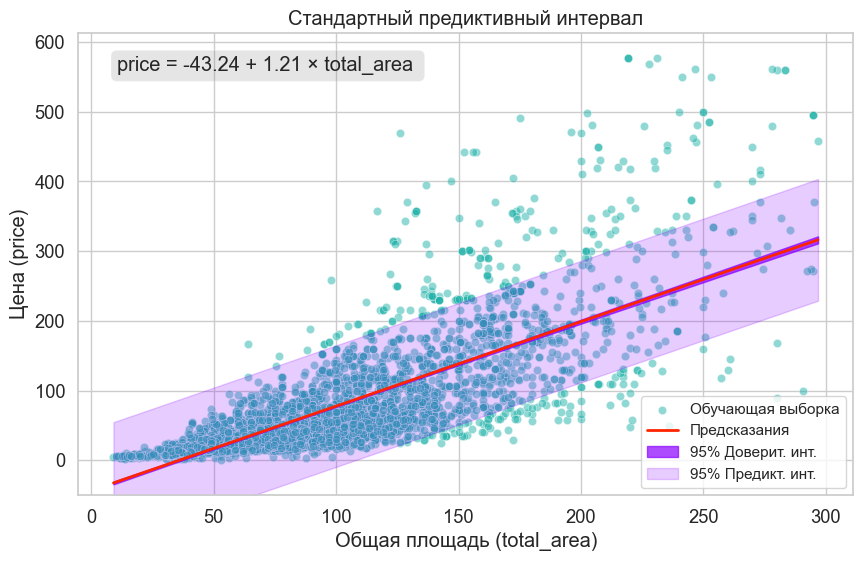

In [15]:
plot_data = pd.concat([grid_data, pred_summary], axis=1)
plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Стандартный предиктивный интервал",
    formula_text=formula_text,
)

Мы видим, что интервал покрывает полоску одной ширины, вне зависимости от того, как распределены наши данные, он не отражает истинное распределение: наши данные __гетероскедастичные__ (это видно по графику, но дальше мы в этом удостоверимся) и это не учитывается. Мы переоцениваем ширину интервала в одном месте и недооцениваем в другом, тем самым неправильно оцениваем риски. Это очень грубая оценка, которая не отражает реальности и не может использоваться для реальной задачи.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">3</span> <span style="color:inherit;">Проверка на гетероскедастичность</span>


Давайте проверим данные на наличие гетероскедастичности.

На предыдущих графиках мы наблюдали увеличение разброса значений целевой переменной с ростом площади. Однако такая картина может возникать и при гомоскедастичности, например, когда разброс связан с другим признаком, который уже включен в модель. В этом случае случайные ошибки могут оказаться гомоскедастичными.

Для проверки гетероскедастичности следует анализировать **графики зависимости остатков модели** $e_i = Y_i - \widehat{y}(x_i)$ (разности между фактическим и предсказанным значением) по обучающей выборке от:

- признаков;
- целевой переменной;
- предсказаний модели;
- номера наблюдения.

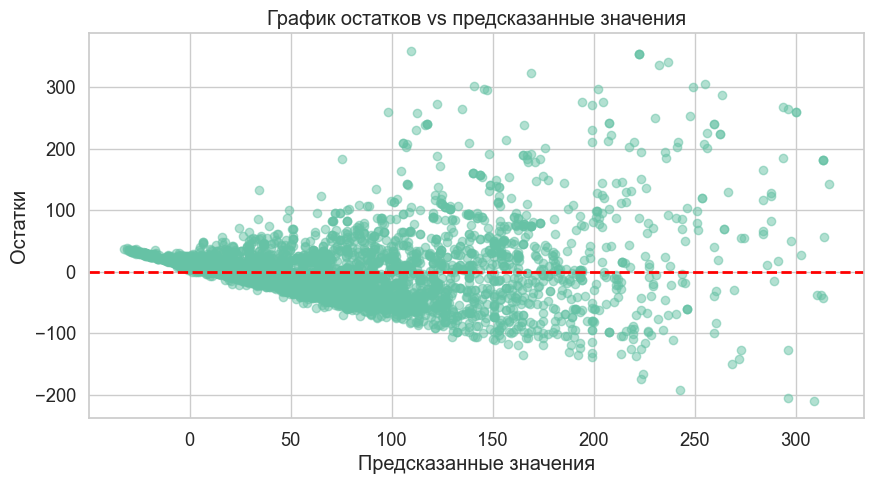

In [16]:
residuals = lm_results.resid  # остатки модели
fitted = lm_results.fittedvalues  # предсказания на трейне
X = lm_results.model.exog  # матрица признаков включая константу

# График остатков
plt.figure(figsize=(10, 5))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--", lw=2)
plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков vs предсказанные значения")
plt.show()

Мы видим явную гетероскедастичность на графике остатков.

Предположение гомоскедастичности состоит в том, что для всех объектов обучающей выборки выполнено 
$$
\mathsf{D}\varepsilon_i = \sigma^2,
$$
то есть ошибки имеют одинаковую дисперсию.  

**Гетероскедастичность** — это ситуация, при которой дисперсия ошибок зависит от наблюдения, признака или таргета.  

На примере с квартирами это означает следующее. Для маленьких квартир ошибка прогноза малая, а для больших — значительно больше. В реальности это может быть по разным причинам: например, большинство маленьких квартир — это студии в новостройках, которые строятся на окраине города, поэтому цены для них больше похожи. А вот большие квартиры оказалось что строят везде, и в центре и на окрание.

**Как проверять данные на гетероскедастичность?**

Особо проверять ее на самом деле и не нужно. Можно построить графики остатков как показано выше. Можно также применить статистические критерии, которые проверяют данные на наличие гетероскедастичность.

Тем не менее, на практике для статистического анализа модели всегда **рекомендуется всегда использовать оценки дисперсии, устойчивые к гетероскедастичности**. Их применение корректно даже в случае гомоскедастичности, соответственно, используя всегда устойчивые оценки мы повышаем надежность модели. 

В данном случае, как мы сказали выше, гетероскедастичность вполне ожидаема. 

**А точно ли с этим что-то нужно делать?**  
- Оценки коэффициентов в модели остаются несмещёнными. Поэтому если в вашей задаче требуется только получить предсказания модели, ничего особенного делать не нужно.
- Но стандартные ошибки оцениваются плохо. В результате доверительные интервалы становятся некорректными и могут давать неверные выводы о значимости факторов. Необходимо использовать специальные оценки, устойчивые к гетероскедастичности.


### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4</span> <span style="color:inherit;">Устойчивые к гетероскедастичности оценки дисперсии</span>

Хорошую оценку ковариационной матрицы вектора $\widehat{\theta}$ в условиях **гетероскедастичности** можно получить двумя способами. Такие оценки обладают свойством состоятельности при нарушении предположения о постоянной дисперсии ошибок, что позволяет получать свойство асимптотической нормальности для оценок коэффициентов.
* Для ранее обученной модели можно вызвать функцию `get_robustcov_results`. Эта функция вычисляет **устойчивые к гетероскедастичности оценки дисперсий** (или, в общем виде, матрицы ковариаций).
* При обучении модели в методе `fit` указать тип ковариационной матрицы с помощью параметра `cov_type` (рассмотрим далее).


> Основные виды оценок:
> 
> 1. **HC0**:  $e_i^2 = \left(Y_i - \widehat{Y}_i\right)^2$ – базовая оценка Уайта (White, 1980).
> 
> 2. Модификации МакКиннона–Уайта:
> 
> $$
\text{HC1: } \frac{n}{n-d} e_i^2, \quad
\text{HC2: } \frac{e_i^2}{1-H_{ii}}, \quad
\text{HC3: } \frac{e_i^2}{(1-H_{ii})^2}
$$
> 
> где $H = X (X^\top X)^{-1} X^\top$. <br/><br/>
> 
> 
> <details>
> <summary>Кликни, чтобы посмотреть другие варианты</summary>
> 
> 6. **"HAC"** – учитывает гетероскедастичность и автокорреляцию.  
> 7. **"cluster"** – оценка с учётом кластерной структуры.  
> 8. **"hac-groupsum"** – HAC с агрегацией по группам (панельные данные).  
> 9. **"hac-panel"** – HAC для панельных данных с временной и кросс-секционной зависимостью.  
> 
> </details>

В дальнейшем будем использовать `cov_type="HC3"` для построения устойчивых предсказательных интервалов.

---

Обучим модель с построением устойчивых к гетероскедастичности оценок дисперсии


In [17]:
linear = smf.ols("price ~ total_area", train)
lm_results_hc3 = linear.fit(cov_type="HC3")

Аналогично можем получить оценку матрицы ковариаций оценки коэффициентов

In [18]:
lm_results_hc3.cov_params()

,Intercept,total_area
Intercept,2.518862,-0.037195
total_area,-0.037195,0.000576


и доверительные интервалы для коэффициентов в условиях гетероскедастичности

In [19]:
lm_results_hc3.conf_int()

,0,1
Intercept,-46.351605,-40.130317
total_area,1.164274,1.258390


Если посмотрим еще раз на интервалы при гомоскедастичности (ниже), увидим, что при использовании оценок дисперсии, устойчивых к гетероскедастичности (выше), интервалы становятся шире

In [20]:
lm_results.conf_int()

,0,1
Intercept,-45.438067,-41.043855
total_area,1.188466,1.234197


#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.1</span> <span style="color:inherit;">Построение доверительных интервалов</span>

Аналогично можно получить и доверительные интервалы для среднего таргета. Но не для предсказательного интервала...

In [21]:
pred_summary = lm_results_hc3.get_prediction(grid_data).summary_frame(alpha=0.05)
pred_summary.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,-32.338975,1.376971,-35.037789,-29.640162,-119.475589,54.797638
1,-28.817548,1.309515,-31.384150,-26.250946,-115.950167,58.315071
2,-25.296121,1.242318,-27.731019,-22.861223,-112.424960,61.832718
3,-21.774694,1.175424,-24.078482,-19.470905,-108.899967,65.350580
4,-18.253267,1.108888,-20.426647,-16.079887,-105.375189,68.868656


**Что поменялось по сравнению со случаем гомоскедастичности?**

1. `mean` &mdash; точечный прогноз

    Не меняется, поскольку коэффициенты модели (`Intercept` и `totsp`) при использовании устойчивых оценок дисперсии остаются теми же. Изменяется только наша оценка их точности. <br/> <br/>

2. `mean_se`, `mean_ci_lower`, `mean_ci_upper` &mdash; доверительный интервал для среднего

    **Изменятся**. Это и есть главная цель использования `cov_type='HC3'`. Эти значения теперь рассчитаны с учетом возможной гетероскедастичности, поэтому они более надежны. Границы доверительного интервала станут шире в тех областях, где разброс данных больше. <br/> <br/>

3. `obs_ci_lower`, `obs_ci_upper` &mdash; предиктивный интервал

    **Изменятся, но здесь есть важный нюанс!** Стандартная формула для предиктивного интервала предполагает **гомоскедастичность** — то есть, что разброс ошибок одинаков для всех наблюдений.

    Когда вы используете `cov_type='HC3'`, мы явно говорим модели: "Я не верю в гомоскедастичность".

    `statsmodels` в этом случае поступает следующим образом:
    *   Для расчета **доверительного интервала** (`mean_ci`) он использует робастную оценку ковариационной матрицы (`HC3`), что корректно.
    *   Для расчета **предиктивного интервала** (`obs_ci`) он комбинирует этот робастный доверительный интервал с общей (усредненной по всем данным) оценкой дисперсии остатков (`scale`), которая по своей сути предполагает гомоскедастичность.

    **Простыми словами:** мы получаем предиктивный интервал, который построен на частично противоречивых предположениях. Он учитывает гетероскедастичность при оценке неопределенности линии регрессии, но не при оценке случайного разброса отдельных точек вокруг этой линии.

Убедимся в этом, построив график

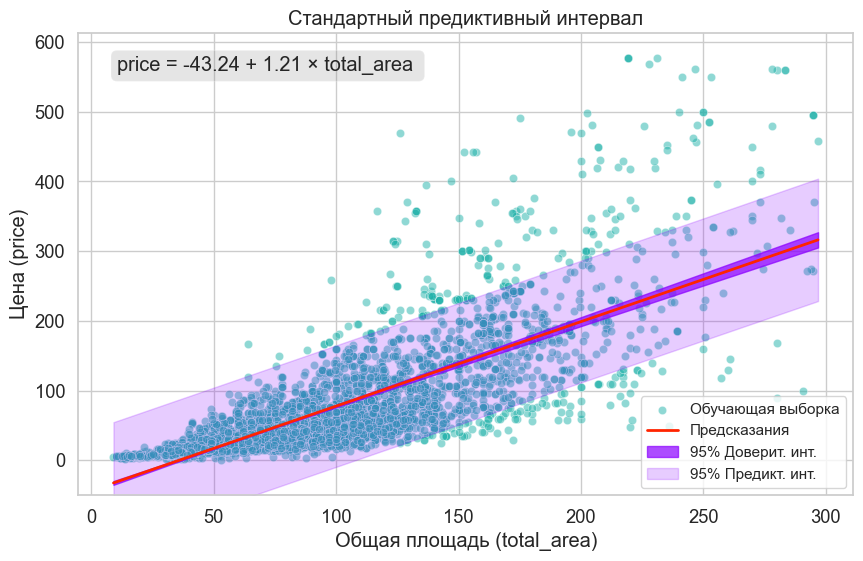

In [22]:
plot_data = pd.concat([grid_data, pred_summary], axis=1)
plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Стандартный предиктивный интервал",
    formula_text=formula_text,
)

**Можно ли доверять результатам?**
* Доверительному интервалу &mdash; да, полностью. Это как раз то, для чего нужны устойчивые оценки дисперсии.
* Предиктивному интервалу &mdash; нет. Он хоть и будет более надежным, чем в модели без `HC3`, но его теоретическая основа неидеальна.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4.2</span> <span style="color:inherit;">Построение предиктивных интервалов с использованием регрессии квадратов остатков</span>

> **Предсказательный интервал с поправкой на гетероскедастичность**
> 
> Пусть $x_0$ &mdash; новый объект и $\widehat{Y}_0 = \widehat{y}(x_0) = x_0^\top\widehat{\theta}$ &mdash; предсказание на нем. Тогда мы можем ожидать, что фактическое значение таргета на новом объекте будет иметь вид
> $$\widehat{Y}_0 = x_0^\top\widehat{\theta} + \varepsilon_0,$$
> где $\varepsilon_0$ &mdash; шум на новом объекте, не зависящий от шума на обучающей выборке (а значит и независимый с $\widehat{\theta}$).
> 
> В случае **гетероскедастичности** дисперсия шума зависит от признаков: $\mathsf{D}\varepsilon_0 = \sigma^2(x_0)$. Тогда дисперсию на новой точке $x_0$ можно представить как
> $$\mathsf{D}\widehat{Y}_0 = x_0^\top\: \mathsf{D}\widehat{\theta}\: x_0 + \sigma^2(x_0),$$
> 
> В качестве оценки этой дисперсии возьмем величину
> $$\widehat{\mathsf{D}}\widehat{Y}_0 = x_0^\top\: \widehat{\mathsf{D}}\widehat{\theta}\: x_0 + \widehat{\sigma}^2(x_0),$$
> где $\widehat{\sigma}^2(x_0)$ — оценка дисперсии ошибки $\sigma^2(x_0)$ в точке $x_0$, а $\widehat{\mathsf{D}}\widehat{\theta}$ — оценка матрица ковариации оценки коэффициентов, которую мы получаем из OLS модели с поправкой на гетероскедастичность. Интервал в таком случае имеет вид
> 
> $$
\left( x_0^\top\widehat{\theta} \ \pm \ T_{n-d, (1+\alpha)/2} \,
\sqrt{x_0^\top\: \widehat{\mathsf{D}}\widehat{\theta}\: x_0 + \widehat{\sigma}^2(x_0)} \right)
$$
> Более строго эта формула получается из рассмотрения распределения остатков, как было показано на лекции.

Стандартный `get_prediction` не позволяет напрямую задать модель для гетероскедастичной дисперсии $\widehat{\sigma}^2(x_0)$. Однако, мы можем "взломать" этот процесс, взяв нужные компоненты из `statsmodels` и добавив свои для оценки дисперсии $\widehat{\sigma}^2(x_0)$.

Идея в том, чтобы использовать `pred_summary` как основу, из которой мы возьмем уже посчитанные для нас `mean` и `mean_se`, а затем вручную заменим гомоскедастичную часть предиктивного интервала на нашу, гетероскедастичную.

**Как построить оценку $\widehat{\sigma}^2(x_0)$?**

Первое, что необходимо сделать для построения такого интервала &mdash; выбрать каким способом мы будем опеределять остатки. 

* Если мы знаем, как они выглядят, например квадратично зависят от параметра, то это знание следует использовать. 

* В противном случае можно смоделировать их следующим образом. Берем $e_i^2$ как новый таргет и строим какую-либо регрессионную модель по признакам $X$. Полученные предсказания этой модели используем как оценку $\widehat{\sigma}^2(x_0)$.

---

Реализуем подход с построением вспомогательной регрессии и посмотрим предсказательные интервалы, полученные с использованием различных моделей.

In [23]:
def calculate_predictive_interval(
    lm_results: RegressionResultsWrapper,
    variance_model: RegressorMixin,
    X_train: pd.DataFrame,
    X_test: pd.DataFrame,
) -> pd.DataFrame:
    """Рассчитывает гетероскедастичный предиктивный интервал для регрессионной модели,
    который учитывает непостоянную дисперсию ошибок (гетероскедастичность).

    Args:
        lm_results: Результаты обученной основной регрессионной модели из `statsmodels`.
        variance_model: Экземпляр НЕОБУЧЕННОЙ регрессионной модели из scikit-learn
            для моделирования дисперсии.
        X_train (pd.DataFrame): Данные (признаки), на которых была обучена
            основная модель `lm_results`. Используются для обучения `variance_model`.
        X_test (pd.DataFrame): Данные (признаки), для которых необходимо построить
            предиктивный интервал.

    Returns:
        pd.DataFrame: DataFrame, аналогичный выводу `.summary_frame()`, но с
            добавленными колонками `obs_ci_lower_het` и `obs_ci_upper_het`,
            содержащими границы гетероскедастичного предиктивного интервала.
    """

    # Таргет вспомогательной модели - квадраты остатков
    resid2 = lm_results.resid**2

    # Обучаем регрессию: resid^2 ~ X_train
    variance_model.fit(X_train, resid2)

    # Получаем стандартные предсказания от statsmodels для X_test
    pred_summary = lm_results.get_prediction(X_test).summary_frame(alpha=0.05)

    # Предсказываем дисперсию ошибки sigma^2(x) для X_test
    sigma2_pred = variance_model.predict(X_test)

    # Убедимся, что предсказанная дисперсия не отрицательна
    sigma2_pred = np.clip(sigma2_pred, a_min=0, a_max=None)

    # Извлекаем дисперсию среднего предсказания, это и есть x_0^T * D(theta_hat) * x_0
    var_mean_pred = pred_summary["mean_se"] ** 2

    # Считаем полную дисперсию предсказания
    total_pred_variance = var_mean_pred + sigma2_pred
    total_pred_se = np.sqrt(total_pred_variance)

    # Находим квантиль t-распределения
    alpha = 0.05
    degrees_freedom = lm_results.df_resid
    t_crit = sps.t.ppf(1 - alpha / 2, df=degrees_freedom)

    # Вычисляем границы нового интервала
    margin_of_error = t_crit * total_pred_se
    pred_summary["obs_ci_lower_het"] = pred_summary["mean"] - margin_of_error
    pred_summary["obs_ci_upper_het"] = pred_summary["mean"] + margin_of_error

    return pred_summary

Определим сетку для построения интервалов

In [24]:
totsp_grid = np.linspace(train["total_area"].min(), train["total_area"].max(), 100)
grid_data = pd.DataFrame({"total_area": totsp_grid})

Попробуем взять в качестве вспомогательной простую линейную регрессию

In [25]:
pred_summary = calculate_predictive_interval(
    lm_results_hc3, LinearRegression(), train[["total_area"]], grid_data[["total_area"]]
)
pred_summary.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper,obs_ci_lower_het,obs_ci_upper_het
0,-32.338975,1.376971,-35.037789,-29.640162,-119.475589,54.797638,-35.038314,-29.639637
1,-28.817548,1.309515,-31.384150,-26.250946,-115.950167,58.315071,-31.384650,-26.250447
2,-25.296121,1.242318,-27.731019,-22.861223,-112.424960,61.832718,-27.731493,-22.860749
3,-21.774694,1.175424,-24.078482,-19.470905,-108.899967,65.350580,-24.078930,-19.470457
4,-18.253267,1.108888,-20.426647,-16.079887,-105.375189,68.868656,-20.427069,-16.079464


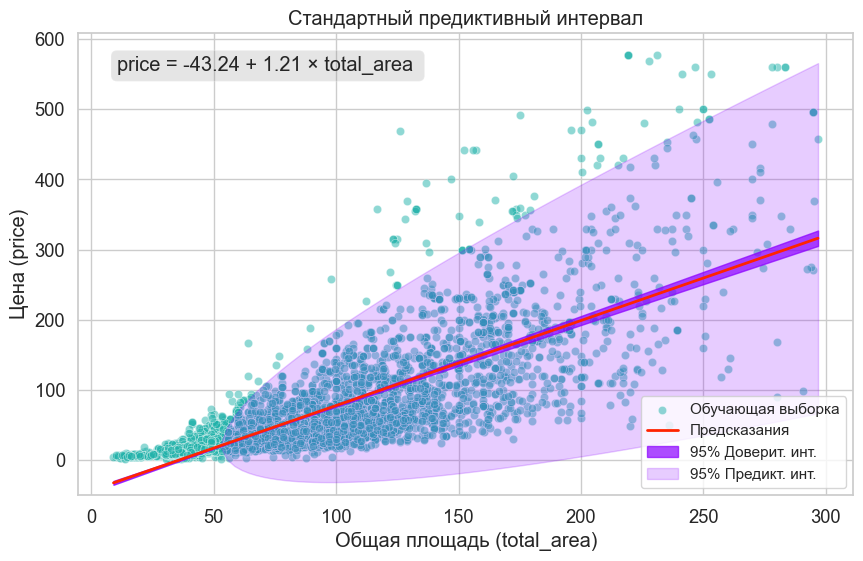

In [26]:
plot_data = pd.concat([grid_data, pred_summary], axis=1)
plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Стандартный предиктивный интервал",
    formula_text=formula_text,
    pred_interval_cols=("obs_ci_lower_het", "obs_ci_upper_het"),
)

Попробуем другие модели, например, взвешенный kNN

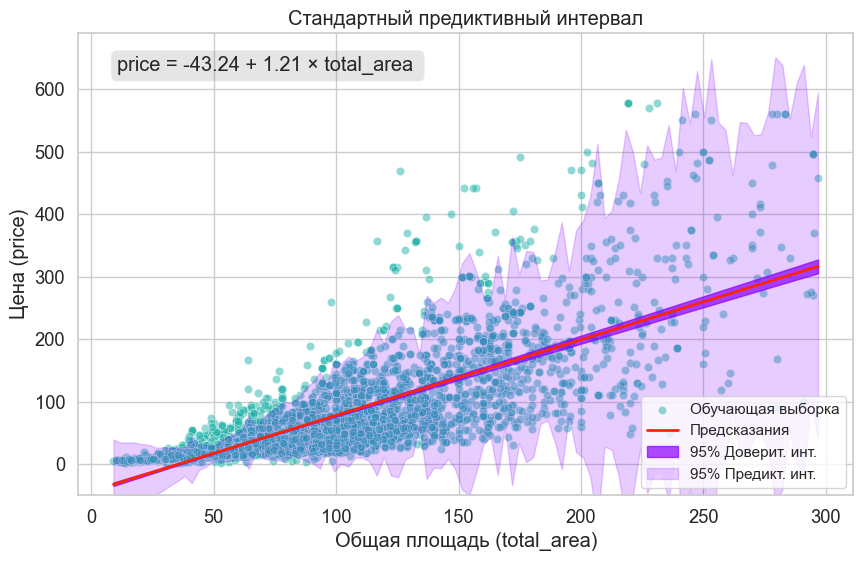

In [27]:
pred_summary = calculate_predictive_interval(
    lm_results_hc3,
    KNeighborsRegressor(n_neighbors=100, weights="distance"),
    train[["total_area"]],
    grid_data[["total_area"]],
)
plot_data = pd.concat([grid_data, pred_summary], axis=1)
plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Стандартный предиктивный интервал",
    formula_text=formula_text,
    pred_interval_cols=("obs_ci_lower_het", "obs_ci_upper_het"),
)

Регрессия Хьюбера с логарифмированием таргета (который квадрат остатков)

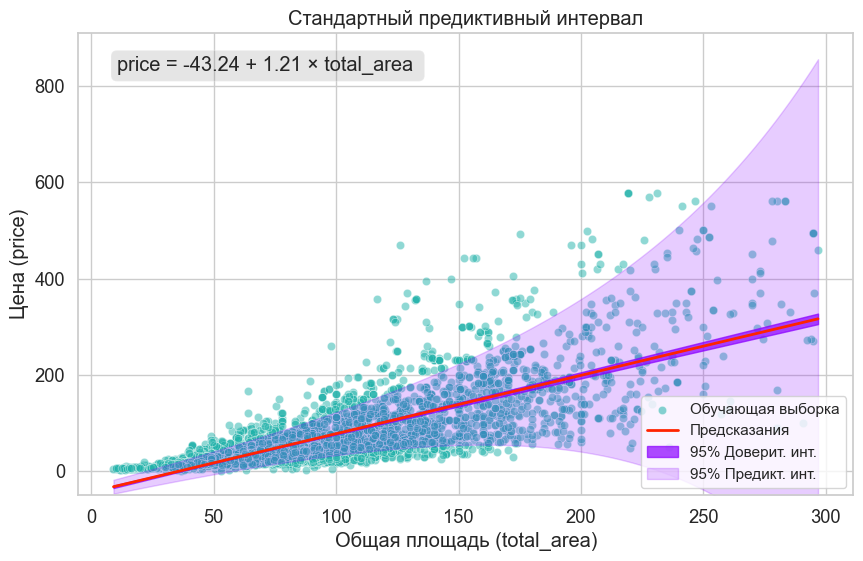

In [28]:
variance_model_huber_sklearn = TransformedTargetRegressor(
    regressor=HuberRegressor(),
    func=lambda y: np.log(y),
    inverse_func=np.exp,
)

pred_summary = calculate_predictive_interval(
    lm_results_hc3, variance_model_huber_sklearn, train[["total_area"]], grid_data[["total_area"]]
)
plot_data = pd.concat([grid_data, pred_summary], axis=1)
plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Стандартный предиктивный интервал",
    formula_text=formula_text,
    pred_interval_cols=("obs_ci_lower_het", "obs_ci_upper_het"),
)

Заметим, что интервалы получились очень разной формы. Так как при значительной гетероскедастичности и также более разреженных хвостах мы можем получить "выбросы" в остатках, можно использовать Huber regression, которая устойчива к ним, или почистить по квантилю.

Предсказательный интервал — это инструмент для **интерпретации конкретного прогноза**, оценки **неопределённости** и проверки адекватности модели на уровне отдельных наблюдений, а не только коэффициентов регрессии.  

Важно отметить, что предсказательный интервал **не улучшает само предсказание**, но позволяет интерпретировать его более осторожно и реалистично, предотвращая иллюзию чрезмерной уверенности.


<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для ШАД для курса ML-1 ШАД</div>